# 5% 600K PEG — Reading $K$ and $n$: Manual Ground Truth vs Automated Repeats

**One-sentence takeaway.** Automated **$n$ is already within ~10%** of the long manual measurement, but **$K$ moves with hit/gap geometry**. Refitting $\tau$–$\dot\gamma$ alone does not fix that; geometry-aware reporting does.

## How to read this notebook
1. **Raw drag** — measured $D=T/\mathrm{RPM}$ for manual and automated (no fitting yet).
2. **Manual ground truth** — $K$, $n$ at hit, then height sensitivity (**geometric error budget**).
3. **Automated production** — live-code $K$, $n$ as bar charts.
4. **Technique comparison** — bar charts of $K$ and $n$ (and % error) across estimators.
5. **Candidates** — practical path toward $\le 10\%$ error.

**Data**
- Manual (~3 h 15 min): `results/auto_runs/5%600KPEG_MANUAL_RAW.csv` — **1 increment = 13 μm**
- Automated (6 experiments): `results/auto_runs/5%600K_PEG_reproducibility_20261119.csv` — **$Z$ in mm** ($-64\to-65$ = 1 mm; steps ≈ 0.02 mm)


## 1. Setup & data load


In [1]:
from __future__ import annotations

import sys
from pathlib import Path
from typing import Any, Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import curve_fit

NOTEBOOK_DIR = Path.cwd().resolve()
ROOT = None
for candidate in [NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent]:
    if (candidate / "src" / "viscometry").is_dir():
        ROOT = candidate
        break
if ROOT is None:
    ROOT = NOTEBOOK_DIR.parents[1]
sys.path.insert(0, str(ROOT / "src"))

from viscometry.rheology.constants import PCT_TO_PA, shear_rate
from viscometry.rheology.live_adapter import filter_measurement_points, predict_cell_rheology
from viscometry.rheology.stress_powerlaw import fit_stress_powerlaw

MANUAL_CSV = ROOT / "results/auto_runs/5%600KPEG_MANUAL_RAW.csv"
AUTO_CSV = ROOT / "results/auto_runs/5%600K_PEG_reproducibility_20261119.csv"
G_REF = 20.0
MANUAL_INC_MM = 0.013
HIT_UNCERT_MM = 0.20
HIT_INC = 0

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.labelsize": 11})
print(f"ROOT = {ROOT}")
print(f"Manual step = {MANUAL_INC_MM*1e3:.0f} um | Auto Z in mm | hit uncertainty budget = +/-{HIT_UNCERT_MM} mm")
assert MANUAL_CSV.exists() and AUTO_CSV.exists()


ROOT = /Users/ianng/Documents/GitHub/Automated_Viscometry
Manual step = 13 um | Auto Z in mm | hit uncertainty budget = +/-0.2 mm


In [2]:
def load_manual(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["Formulation"] = df["Formulation"].ffill()
    for col in ["Increment", "speed_RPM", "SR_1/s", "Viscosity_cP", "Torque_%", "SS_dyne/cm2", "Accuracy_cP"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    missing = df["SS_dyne/cm2"].isna()
    df.loc[missing, "SS_dyne/cm2"] = df.loc[missing, "Viscosity_cP"] * df.loc[missing, "SR_1/s"] / 100.0
    df["tau_Pa"] = df["SS_dyne/cm2"] / 10.0
    df["gamma_dot_1_s"] = df["SR_1/s"]
    df["drag"] = df["Torque_%"] / df["speed_RPM"]
    df["h_rel_mm"] = (df["Increment"] - HIT_INC) * MANUAL_INC_MM
    return df


def load_auto_experiments(path: Path) -> List[Dict[str, Any]]:
    raw = path.read_text().splitlines()
    chunks: List[pd.DataFrame] = []
    cur_ts = None
    header = None
    buf: List[List[str]] = []

    def flush() -> None:
        nonlocal buf
        if buf and header is not None:
            d = pd.DataFrame(buf, columns=header)
            d["timestamp"] = cur_ts
            chunks.append(d)
        buf = []

    for line in raw:
        if line.startswith("# Timestamp:"):
            flush()
            cur_ts = line.split("Timestamp:")[1].strip().rstrip(",")
            continue
        if line.startswith("cell,"):
            flush()
            header = line.split(",")
            continue
        parts = line.split(",")
        if header is None or len(parts) != len(header):
            continue
        try:
            float(parts[1]); float(parts[2]); float(parts[4])
        except ValueError:
            continue
        if parts[0] in ("", "nan"):
            continue
        buf.append(parts)
    flush()

    auto = pd.concat(chunks, ignore_index=True)
    for col in ["cell", "Z_Height_mm", "RPM", "Elapsed_Time_s", "Torque_%", "Rotational_Drag"]:
        auto[col] = pd.to_numeric(auto[col], errors="coerce")
    auto = auto.dropna(subset=["cell", "Z_Height_mm", "RPM", "Torque_%"])
    auto["cell"] = auto["cell"].astype(int)

    exps: List[Dict[str, Any]] = []
    for (ts, cell), g in auto.groupby(["timestamp", "cell"]):
        g_ord = g.reset_index(drop=True)
        zz = g_ord["Z_Height_mm"].to_numpy()
        breaks = [0]
        for i in range(1, len(zz)):
            if zz[i] - zz[i - 1] > 0.05:
                breaks.append(i)
        breaks.append(len(zz))
        multi = len(breaks) > 2
        for j, (a, b) in enumerate(zip(breaks[:-1], breaks[1:])):
            sub = g_ord.iloc[a:b].copy()
            name = f"{ts}_cell{cell}" + (f"_seg{j}" if multi else "")
            short = f"c{cell}" + (f"s{j}" if multi else "")
            if str(ts).startswith("20261125"):
                short = f"c{cell}_d2"
            exps.append({"name": name, "short": short, "timestamp": ts, "cell": int(cell), "df": sub})
    return exps


def hit_z_from_flags(df: pd.DataFrame) -> float:
    conf = df[df["Confirm_hit"].astype(str).str.upper().eq("HIT")]
    if len(conf):
        return float(conf["Z_Height_mm"].max())
    hits = df[df["Hit_Detected"].astype(str).str.upper().eq("TRUE")]
    if len(hits):
        return float(hits["Z_Height_mm"].max())
    return float(df["Z_Height_mm"].min())


manual = load_manual(MANUAL_CSV)
exps = load_auto_experiments(AUTO_CSV)
print(f"Manual: {len(manual)} rows, {manual['Increment'].nunique()} increments, RPMs={sorted(manual['speed_RPM'].unique())}")
print(f"Auto: {len(exps)} experiments")
for e in exps:
    d = e["df"]
    zs = np.sort(d["Z_Height_mm"].unique())
    print(f"  {e['short']:8s}  Z {zs.max():.2f}->{zs.min():.2f} mm  span={zs.max()-zs.min():.3f} mm  nZ={len(zs)}")


Manual: 130 rows, 26 increments, RPMs=[np.int64(5), np.int64(7), np.int64(9), np.int64(11), np.int64(13)]
Auto: 6 experiments
  c1        Z -65.60->-65.96 mm  span=0.360 mm  nZ=19
  c2        Z -65.40->-65.80 mm  span=0.400 mm  nZ=21
  c3        Z -65.30->-65.66 mm  span=0.360 mm  nZ=19
  c7        Z -65.54->-65.94 mm  span=0.400 mm  nZ=21
  c8        Z -65.38->-65.62 mm  span=0.240 mm  nZ=13
  c7_d2     Z -65.54->-65.94 mm  span=0.400 mm  nZ=21


## 2. Raw rotational drag (look at the data first)

Rotational drag $D = T_{\%}/\mathrm{RPM}$ is the shared measured signal.

- **Manual:** $D$ vs $h-h_{\mathrm{hit}}$ (13 μm per increment).
- **Automated:** same relative-gap axis after subtracting each run's flagged hit $Z$.

Pink band = $\pm 0.20\,\mathrm{mm}$ hit-uncertainty budget.


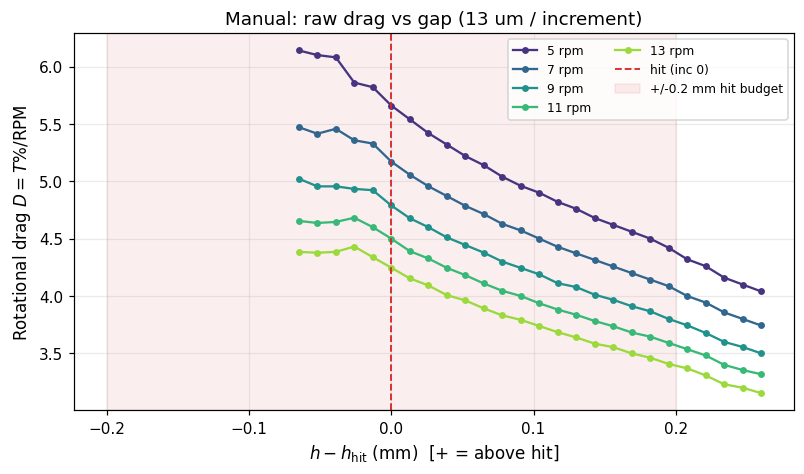

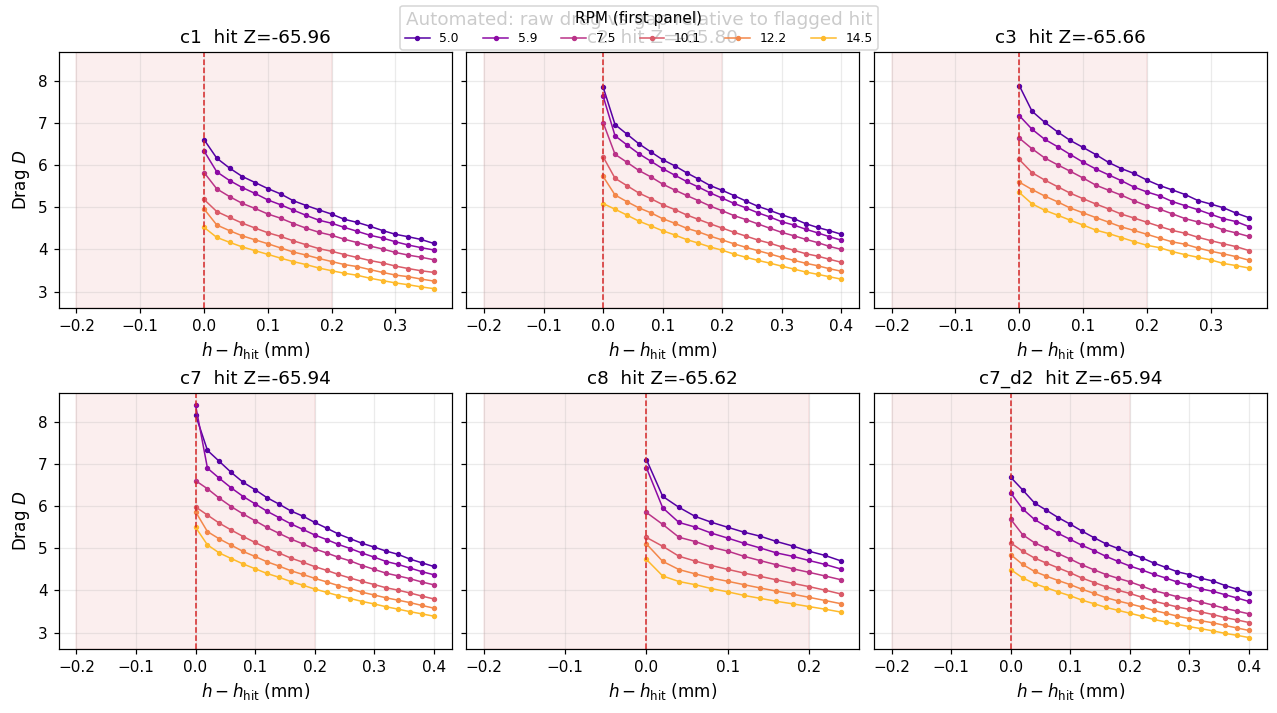

Both campaigns: drag rises as h_rel decreases (deeper into the sample).


In [3]:
# Manual raw drag
fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
rpms_m = sorted(manual["speed_RPM"].unique())
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(rpms_m)))
for rpm, color in zip(rpms_m, cmap):
    sub = manual[manual["speed_RPM"] == rpm].sort_values("h_rel_mm")
    ax.plot(sub["h_rel_mm"], sub["drag"], "o-", ms=3.5, color=color, label=f"{int(rpm)} rpm")
ax.axvline(0.0, color="C3", ls="--", lw=1.2, label="hit (inc 0)")
ax.axvspan(-HIT_UNCERT_MM, HIT_UNCERT_MM, color="C3", alpha=0.08, label=f"+/-{HIT_UNCERT_MM} mm hit budget")
ax.set_xlabel(r"$h - h_{\mathrm{hit}}$ (mm)  [+ = above hit]")
ax.set_ylabel(r"Rotational drag $D = T\%/\mathrm{RPM}$")
ax.set_title("Manual: raw drag vs gap (13 um / increment)")
ax.legend(ncols=2, fontsize=8, loc="best")
plt.show()

# Automated raw drag on the same relative-gap axis
fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.2), constrained_layout=True, sharey=True)
axes = axes.ravel()
for ax, exp in zip(axes, exps):
    d = exp["df"].copy()
    hz = hit_z_from_flags(d)
    d["h_rel_mm"] = d["Z_Height_mm"] - hz
    rpms = sorted(d["RPM"].unique())
    colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(rpms)))
    for rpm, color in zip(rpms, colors):
        sub = d[np.isclose(d["RPM"], rpm)].sort_values("h_rel_mm")
        drag = sub["Rotational_Drag"]
        if drag.isna().all():
            drag = sub["Torque_%"] / sub["RPM"]
        ax.plot(sub["h_rel_mm"], drag, "o-", ms=2.5, color=color, lw=1.0, label=f"{rpm:.1f}")
    ax.axvline(0.0, color="C3", ls="--", lw=1.0)
    ax.axvspan(-HIT_UNCERT_MM, HIT_UNCERT_MM, color="C3", alpha=0.08)
    ax.set_title(f"{exp['short']}  hit Z={hz:.2f}")
    ax.set_xlabel(r"$h - h_{\mathrm{hit}}$ (mm)")
axes[0].set_ylabel("Drag $D$")
axes[3].set_ylabel("Drag $D$")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncols=6, fontsize=8, title="RPM (first panel)")
fig.suptitle("Automated: raw drag vs gap relative to flagged hit", y=1.02)
plt.show()
print("Both campaigns: drag rises as h_rel decreases (deeper into the sample).")


## 3. Manual ground truth $K$, $n$ and geometric error

**Fit (standard Ostwald–de Waele over the measured window):** $\tau = K\,\dot\gamma^{n}$ via log–OLS.

**Ground truth gap** = increment 0 (hit). The next cell shows the flow curve and how $K$, $n$ shift with height.


Manual ground truth @ hit (inc 0, h_rel=0):
  K = 11.278 Pa*s^n
  n = 0.700
  eta_app(20 1/s) = 4585 cP
  R2 = 0.99958


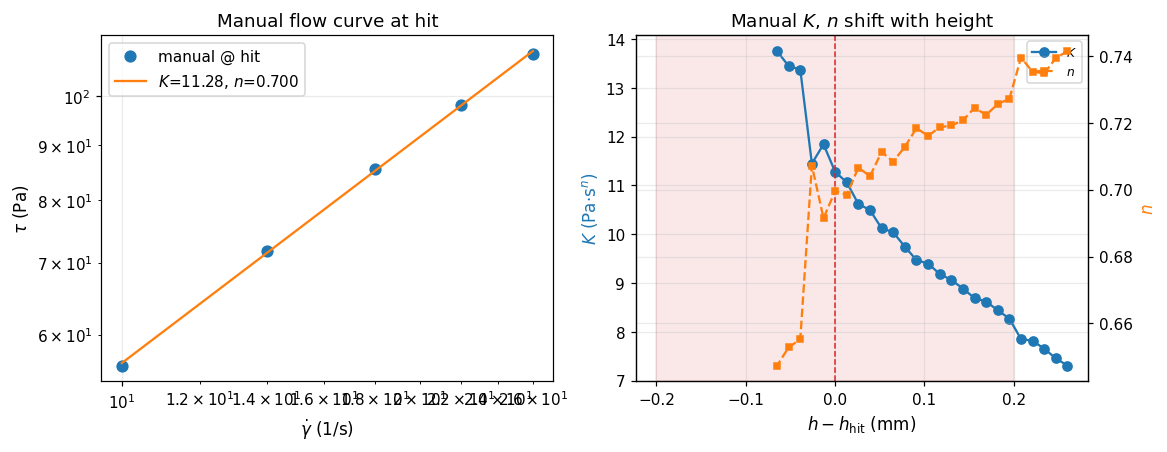

In [4]:
def eta_app_cp(K: float, n: float, g: float = G_REF) -> float:
    return float(K * (g ** (n - 1.0)) * 1000.0)


def pct_err(pred: float, truth: float) -> float:
    return float(100.0 * (pred - truth) / truth)


inc_rows = []
for inc, g in manual.groupby("Increment"):
    pl = fit_stress_powerlaw(g["gamma_dot_1_s"], g["tau_Pa"])
    inc_rows.append({
        "Increment": int(inc),
        "h_rel_mm": (int(inc) - HIT_INC) * MANUAL_INC_MM,
        "K": pl["K_stress"],
        "n": pl["n_stress"],
        "R2": pl["R2_stress"],
        "eta20_cP": eta_app_cp(pl["K_stress"], pl["n_stress"]),
        "mean_drag": float(g["drag"].mean()),
    })
inc_fit = pd.DataFrame(inc_rows).sort_values("h_rel_mm", ascending=False).reset_index(drop=True)

gt = inc_fit.loc[inc_fit["Increment"] == HIT_INC].iloc[0]
GT_K, GT_n, GT_ETA20 = float(gt["K"]), float(gt["n"]), float(gt["eta20_cP"])
print("Manual ground truth @ hit (inc 0, h_rel=0):")
print(f"  K = {GT_K:.3f} Pa*s^n")
print(f"  n = {GT_n:.3f}")
print(f"  eta_app(20 1/s) = {GT_ETA20:.0f} cP")
print(f"  R2 = {gt['R2']:.5f}")

m_hit = manual[manual["Increment"] == HIT_INC]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), constrained_layout=True)
g_line = np.logspace(np.log10(m_hit["gamma_dot_1_s"].min()), np.log10(m_hit["gamma_dot_1_s"].max()), 50)
axes[0].loglog(m_hit["gamma_dot_1_s"], m_hit["tau_Pa"], "o", ms=7, label="manual @ hit")
axes[0].loglog(g_line, GT_K * g_line ** GT_n, "-", label=fr"$K$={GT_K:.2f}, $n$={GT_n:.3f}")
axes[0].set_xlabel(r"$\dot\gamma$ (1/s)")
axes[0].set_ylabel(r"$\tau$ (Pa)")
axes[0].set_title("Manual flow curve at hit")
axes[0].legend()

axes[1].plot(inc_fit["h_rel_mm"], inc_fit["K"], "o-", color="C0", label="$K$")
axn = axes[1].twinx()
axn.plot(inc_fit["h_rel_mm"], inc_fit["n"], "s--", color="C1", ms=4, label="$n$")
axes[1].axvline(0.0, color="C3", ls="--", lw=1)
axes[1].axvspan(-HIT_UNCERT_MM, HIT_UNCERT_MM, color="C3", alpha=0.10)
axes[1].set_xlabel(r"$h - h_{\mathrm{hit}}$ (mm)")
axes[1].set_ylabel(r"$K$ (Pa·s$^n$)", color="C0")
axn.set_ylabel(r"$n$", color="C1")
axes[1].set_title("Manual $K$, $n$ shift with height")
h1, l1 = axes[1].get_legend_handles_labels()
h2, l2 = axn.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc="best", fontsize=8)
plt.show()


### Unavoidable geometric error budget

If the hit is wrong by $\Delta h$, $(K,n)$ are taken from the wrong place on the height curve above.  
We read the manual $K(h)$ and $n(h)$ at $\pm 0.20\,\mathrm{mm}$ (practical hit budget) and at ~40 μm (where auto-like $K$ already appears).


Geometric sensitivity (same fluid + fit; only gap changes):


,condition,h_rel_mm,K,n,dK_%_vs_hit,dn_%_vs_hit,eta20_cP,d_eta20_%_vs_hit
0,hit (0),0.000,11.278,0.700,0.000,0.000,4585.025,0.000
1,+0.20 mm shallower,0.200,8.109,0.732,-28.101,4.622,3631.897,-20.788
2,-0.20 mm deeper [clipped],-0.065,13.750,0.647,21.917,-7.456,4781.340,4.282
3,-0.039 mm (~inc -3),-0.039,13.372,0.655,18.564,-6.329,4760.910,3.836
4,-0.065 mm (deepest manual),-0.065,13.750,0.647,21.917,-7.456,4781.340,4.282


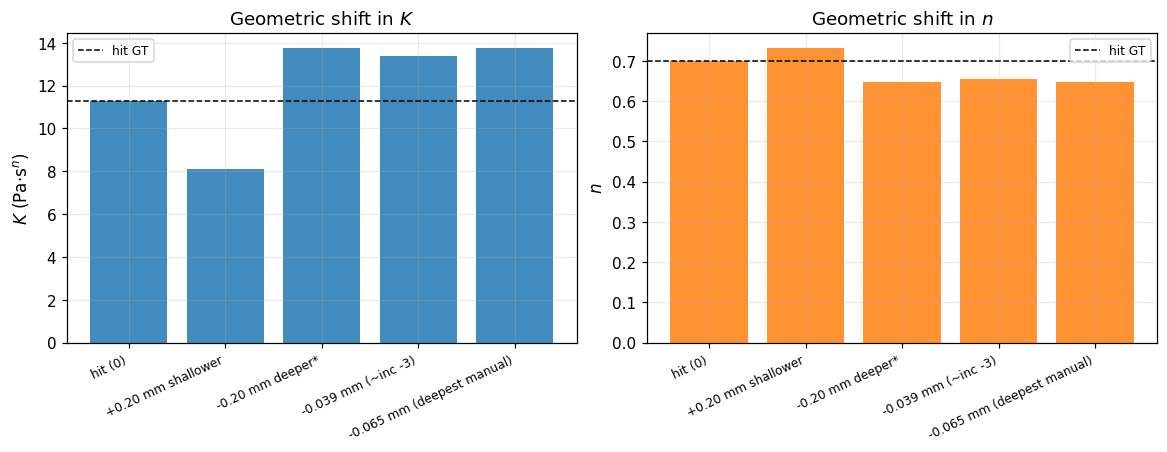


*** Geometric error budget (+/-0.20 mm hit uncertainty, clipped to measured gaps) ***
  K range: 8.11 .. 13.75 Pa*s^n  (hit 11.28)  => up to 28.1% |dK|
  n range: 0.647 .. 0.732  (hit 0.700)  => up to 7.5% |dn|
  Note: deepest manual point is only -0.065 mm; '-0.20 mm deeper' is clipped.
  Even -0.039 mm (~2 auto steps) already moves K by +18.6%.


In [5]:
def kn_at_h(h_mm: float) -> Tuple[float, float]:
    h = inc_fit["h_rel_mm"].to_numpy(float)
    K = inc_fit["K"].to_numpy(float)
    n = inc_fit["n"].to_numpy(float)
    order = np.argsort(h)
    return float(np.interp(h_mm, h[order], K[order])), float(np.interp(h_mm, h[order], n[order]))


h_min = float(inc_fit["h_rel_mm"].min())
h_max = float(inc_fit["h_rel_mm"].max())
probe_hs = [
    ("hit (0)", 0.0),
    ("+0.20 mm shallower", +HIT_UNCERT_MM),
    ("-0.20 mm deeper", -HIT_UNCERT_MM),
    ("-0.039 mm (~inc -3)", -0.039),
    ("-0.065 mm (deepest manual)", h_min),
]

geo_rows = []
for label, h in probe_hs:
    h_clip = float(np.clip(h, h_min, h_max))
    K, n = kn_at_h(h_clip)
    clipped = abs(h_clip - h) > 1e-9
    geo_rows.append({
        "condition": label + (" [clipped]" if clipped else ""),
        "h_rel_mm": h_clip,
        "K": K,
        "n": n,
        "dK_%_vs_hit": pct_err(K, GT_K),
        "dn_%_vs_hit": pct_err(n, GT_n),
        "eta20_cP": eta_app_cp(K, n),
        "d_eta20_%_vs_hit": pct_err(eta_app_cp(K, n), GT_ETA20),
    })
geo = pd.DataFrame(geo_rows)
print("Geometric sensitivity (same fluid + fit; only gap changes):")
display(geo.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), constrained_layout=True)
labels = [r.replace(" [clipped]", "*") for r in geo["condition"]]
x = np.arange(len(labels))
axes[0].bar(x, geo["K"], color="C0", alpha=0.85)
axes[0].axhline(GT_K, color="k", ls="--", lw=1, label="hit GT")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=25, ha="right", fontsize=8)
axes[0].set_ylabel(r"$K$ (Pa·s$^n$)")
axes[0].set_title("Geometric shift in $K$")
axes[0].legend(fontsize=8)

axes[1].bar(x, geo["n"], color="C1", alpha=0.85)
axes[1].axhline(GT_n, color="k", ls="--", lw=1, label="hit GT")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=25, ha="right", fontsize=8)
axes[1].set_ylabel(r"$n$")
axes[1].set_title("Geometric shift in $n$")
axes[1].legend(fontsize=8)
plt.show()

K_lo, n_lo = kn_at_h(max(-HIT_UNCERT_MM, h_min))
K_hi, n_hi = kn_at_h(min(+HIT_UNCERT_MM, h_max))
print("\n*** Geometric error budget (+/-0.20 mm hit uncertainty, clipped to measured gaps) ***")
print(
    f"  K range: {min(K_lo,K_hi):.2f} .. {max(K_lo,K_hi):.2f} Pa*s^n  (hit {GT_K:.2f})"
    f"  => up to {max(abs(pct_err(K_lo,GT_K)), abs(pct_err(K_hi,GT_K))):.1f}% |dK|"
)
print(
    f"  n range: {min(n_lo,n_hi):.3f} .. {max(n_lo,n_hi):.3f}  (hit {GT_n:.3f})"
    f"  => up to {max(abs(pct_err(n_lo,GT_n)), abs(pct_err(n_hi,GT_n))):.1f}% |dn|"
)
print("  Note: deepest manual point is only -0.065 mm; '-0.20 mm deeper' is clipped.")
print(f"  Even -0.039 mm (~2 auto steps) already moves K by {pct_err(kn_at_h(-0.039)[0], GT_K):+.1f}%.")


## 4. Automated production fits (live code)

Each experiment → `predict_cell_rheology` (hyperbola drag → hit stress → log–OLS).  
Mild shear-thinning pathway: $n = n_{\mathrm{stress}}$, $K = K_{\mathrm{stress}}$.


,experiment,full_name,hit_z,pathway,n,K,K_Pas_n,R2,eta20_cP,err_n_%,err_K_%
0,c1,20261119_104557_cell1,-65.96,mild_shear_thinning,0.657,14.359,8.346,0.999,5133.781,-6.129,27.314
1,c2,20261119_104557_cell2,-65.80,mild_shear_thinning,0.630,17.720,11.412,0.999,5848.366,-9.946,57.112
2,c3,20261119_104557_cell3,-65.66,mild_shear_thinning,0.656,16.145,9.967,1.000,5762.599,-6.209,43.148
3,c7,20261119_104557_cell7,-65.94,mild_shear_thinning,0.640,17.283,11.109,0.997,5873.965,-8.547,53.241
4,c8,20261119_104557_cell8,-65.62,mild_shear_thinning,0.653,14.115,8.476,1.000,4983.877,-6.724,25.146
5,c7_d2,20261125_162622_cell7,-65.94,mild_shear_thinning,0.650,15.081,9.369,0.999,5289.994,-7.040,33.716


Auto production: n CV=1.5%  mean|err|=7.4%  |  K CV=8.7%  mean|err|=39.9%


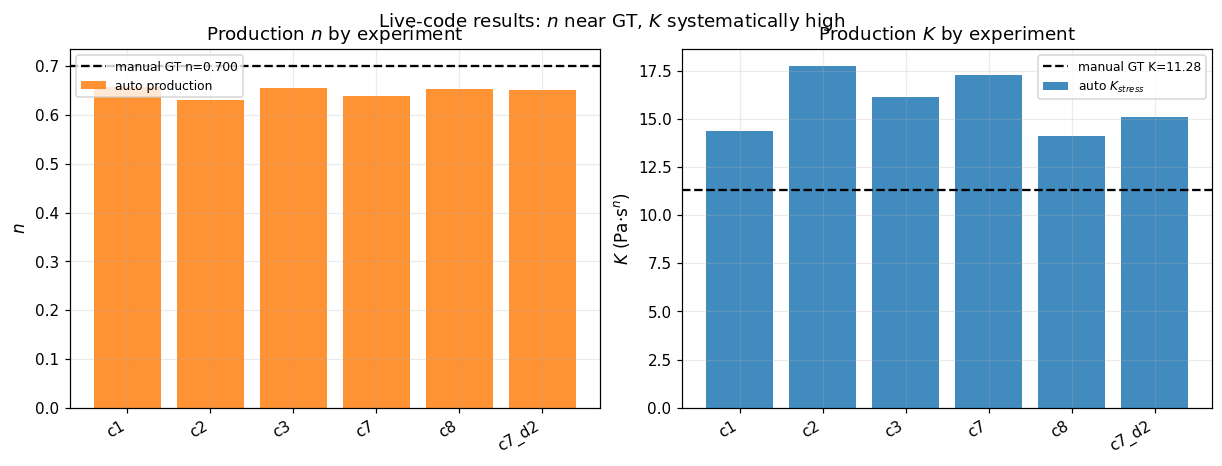

In [6]:
def points_from_exp(exp: Dict[str, Any]) -> Tuple[List[Dict[str, Any]], float, List[float]]:
    d = exp["df"]
    cell = int(exp["cell"])
    hz = hit_z_from_flags(d)
    points = []
    for _, r in d.iterrows():
        rpm = float(r["RPM"])
        torque = float(r["Torque_%"])
        drag = float(r["Rotational_Drag"]) if pd.notna(r["Rotational_Drag"]) else abs(torque) / rpm
        points.append({
            "cell_id": cell,
            "height": float(r["Z_Height_mm"]),
            "rpm": rpm,
            "torque_percent": torque,
            "rotational_drag": drag,
        })
    return points, hz, sorted(d["RPM"].unique().tolist())


prod_rows = []
per_rpm_store: Dict[str, Dict[float, Dict[str, Any]]] = {}
for exp in exps:
    points, hz, rpms = points_from_exp(exp)
    per_rpm, summary = predict_cell_rheology(
        exp["cell"], rpms, points, torque_floor_pct=0.0, hit_point_z=hz
    )
    per_rpm_store[exp["name"]] = per_rpm
    prod_rows.append({
        "experiment": exp["short"],
        "full_name": exp["name"],
        "hit_z": hz,
        "pathway": summary.get("pathway"),
        "n": summary.get("n_stress"),
        "K": summary.get("K_stress"),
        "K_Pas_n": summary.get("K_Pas_n"),
        "R2": summary.get("R2_stress"),
        "eta20_cP": eta_app_cp(summary["K_stress"], summary["n_stress"])
        if summary.get("K_stress") and summary.get("n_stress") else np.nan,
        "err_n_%": pct_err(summary.get("n_stress"), GT_n) if summary.get("n_stress") else np.nan,
        "err_K_%": pct_err(summary.get("K_stress"), GT_K) if summary.get("K_stress") else np.nan,
    })

prod = pd.DataFrame(prod_rows)
display(prod.round(3))


def cv_pct(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(100.0 * s.std(ddof=0) / s.mean()) if len(s) and s.mean() else np.nan


print(
    f"Auto production: n CV={cv_pct(prod['n']):.1f}%  mean|err|={prod['err_n_%'].abs().mean():.1f}%  |  "
    f"K CV={cv_pct(prod['K']):.1f}%  mean|err|={prod['err_K_%'].abs().mean():.1f}%"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), constrained_layout=True)
x = np.arange(len(prod))
axes[0].bar(x, prod["n"], color="C1", alpha=0.85, label="auto production")
axes[0].axhline(GT_n, color="k", ls="--", label=f"manual GT n={GT_n:.3f}")
axes[0].set_xticks(x)
axes[0].set_xticklabels(prod["experiment"], rotation=30, ha="right")
axes[0].set_ylabel(r"$n$")
axes[0].set_title("Production $n$ by experiment")
axes[0].legend(fontsize=8)

axes[1].bar(x, prod["K"], color="C0", alpha=0.85, label=r"auto $K_{stress}$")
axes[1].axhline(GT_K, color="k", ls="--", label=f"manual GT K={GT_K:.2f}")
axes[1].set_xticks(x)
axes[1].set_xticklabels(prod["experiment"], rotation=30, ha="right")
axes[1].set_ylabel(r"$K$ (Pa·s$^n$)")
axes[1].set_title("Production $K$ by experiment")
axes[1].legend(fontsize=8)
fig.suptitle("Live-code results: $n$ near GT, $K$ systematically high", y=1.02)
plt.show()


## 5. Exploratory techniques — $K$ and $n$ as bars

| Label | Meaning |
|---|---|
| **prod (hyp+logOLS)** | Live code |
| **raw+logOLS** | Raw torque at hit $Z$, log–OLS |
| **hyp+NLS** | Hyperbola $\tau$, nonlinear LS |
| **hyp+pairwise n** | Scale-free pairwise $n$, then geometric-mean $K$ |
| **drag-matched** | Same auto $(K,n)$ as production; **% error vs manual gap with similar drag** |
| **shared-n + eta-cal** | One shared $n$; magnitude scaled so mean $\eta_{20}$ matches manual |

**eta-calibrated** = divide auto $\eta_{20}$ by the mean auto/manual $\eta_{20}$ ratio. This calibrates magnitude only; it does **not** trade $n$ accuracy for $K$.


Technique means across 6 automated experiments:


,technique,n_mean,n_std,K_mean,K_std,abs_err_n,abs_err_K,eta20_mean
0,prod (hyp+logOLS),0.648,0.011,15.784,1.512,7.432,39.946,5482.097
1,raw+logOLS,0.618,0.032,17.487,2.601,11.688,55.051,5526.192
2,hyp+NLS,0.643,0.011,16.010,1.435,8.116,41.954,5484.357
3,hyp+pairwise n,0.647,0.010,15.831,1.372,7.562,40.364,5487.403
4,drag-matched (err vs matched gap),0.648,0.011,15.784,1.512,1.315,14.788,5482.097
5,shared-n + eta-cal,0.647,0.000,13.215,0.948,7.562,17.173,4585.025


Shared n = 0.6466 | mean auto/manual eta20 scale = 1.196

Drag-match geometry (auto near-hit drag -> closest manual increment):


,experiment,matched_inc,matched_h_um,auto_K,manual_K_matched
0,c1,-5,-65.0,14.36,13.75
1,c2,-5,-65.0,17.72,13.75
2,c3,-5,-65.0,16.14,13.75
3,c7,-5,-65.0,17.28,13.75
4,c8,-5,-65.0,14.11,13.75
5,c7_d2,-5,-65.0,15.08,13.75


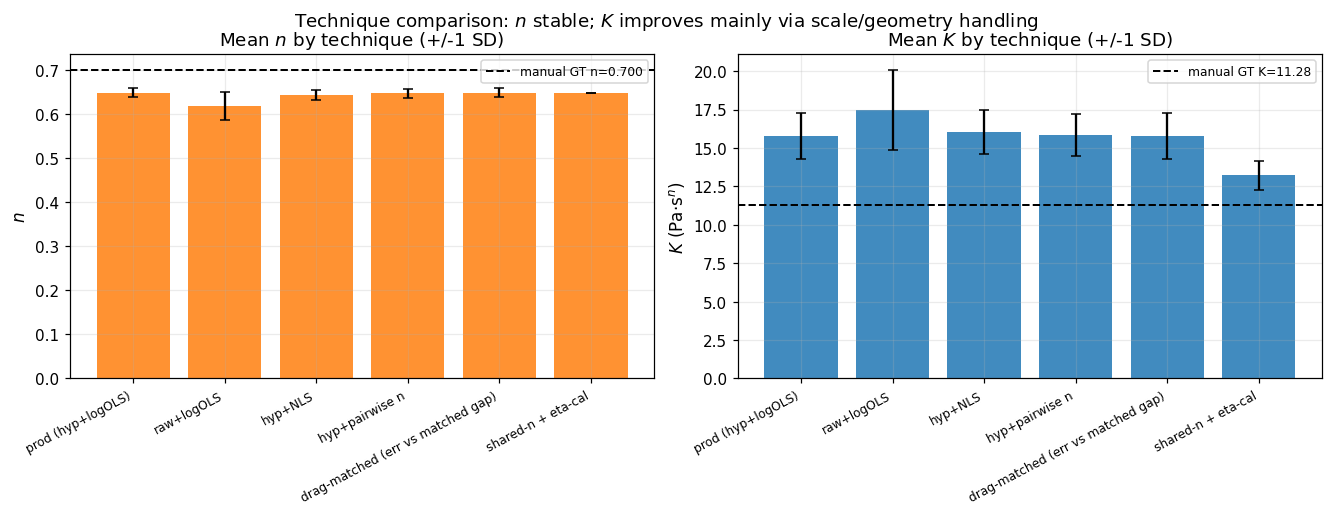

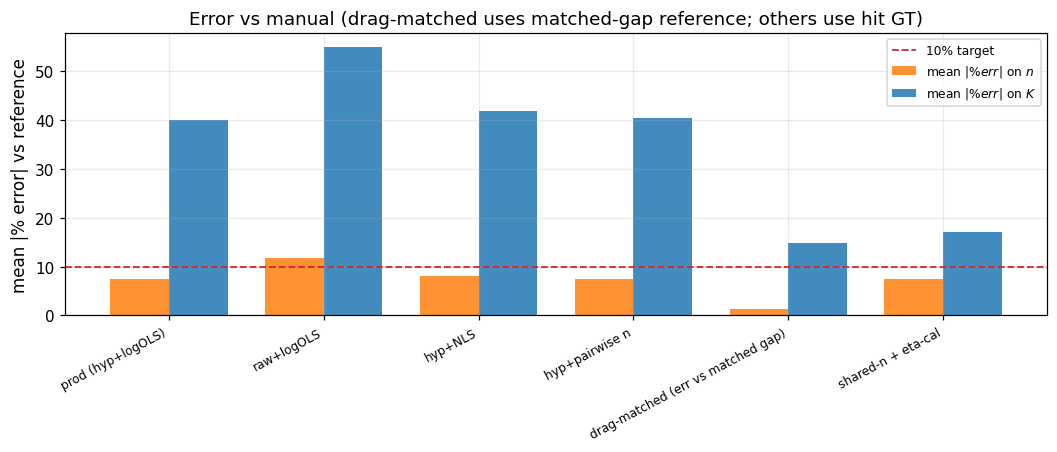

In [7]:
def fit_nls_powerlaw(g: np.ndarray, t: np.ndarray) -> Dict[str, float]:
    g = np.asarray(g, float)
    t = np.asarray(t, float)
    m = np.isfinite(g) & np.isfinite(t) & (g > 0) & (t > 0)
    g, t = g[m], t[m]
    seed = fit_stress_powerlaw(g, t)

    def model(x, K, n):
        return K * np.power(x, n)

    popt, _ = curve_fit(
        model, g, t,
        p0=[seed["K_stress"], seed["n_stress"]],
        bounds=([1e-6, 0.05], [1e3, 1.5]),
        maxfev=20000,
    )
    return {"K": float(popt[0]), "n": float(popt[1])}


def fit_pairwise_n(g: np.ndarray, t: np.ndarray) -> Dict[str, float]:
    g = np.asarray(g, float)
    t = np.asarray(t, float)
    m = np.isfinite(g) & np.isfinite(t) & (g > 0) & (t > 0)
    g, t = g[m], t[m]
    ns = []
    for i in range(len(g)):
        for j in range(i + 1, len(g)):
            dg = np.log(g[i] / g[j])
            if abs(dg) < 1e-9:
                continue
            ns.append(np.log(t[i] / t[j]) / dg)
    n = float(np.median(ns))
    Ki = t / np.power(g, n)
    K = float(np.exp(np.mean(np.log(Ki))))
    return {"K": K, "n": n}


def stresses_for_exp(exp, per_rpm):
    points, hz, rpms = points_from_exp(exp)
    g, th, tr = [], [], []
    for rpm in rpms:
        fit = per_rpm[rpm]
        if not fit.get("success"):
            continue
        g.append(float(shear_rate(rpm)))
        th.append(float(fit["tau_Pa_hit"]))
        pts = filter_measurement_points(points, exp["cell"], float(rpm))
        pts = [p for p in pts if p["height"] >= hz - 1e-9] or pts
        pnear = min(pts, key=lambda p: abs(p["height"] - hz))
        tr.append(PCT_TO_PA * float(pnear["torque_percent"]))
    return np.asarray(g), np.asarray(th), np.asarray(tr)


tech_rows = []
match_meta = []
for exp, prow in zip(exps, prod.itertuples(index=False)):
    g, th, tr = stresses_for_exp(exp, per_rpm_store[exp["name"]])
    methods = {
        "prod (hyp+logOLS)": {"K": prow.K, "n": prow.n},
        "raw+logOLS": fit_stress_powerlaw(g, tr),
        "hyp+NLS": fit_nls_powerlaw(g, th),
        "hyp+pairwise n": fit_pairwise_n(g, th),
    }
    for name, fit in methods.items():
        K = float(fit.get("K", fit.get("K_stress")))
        n = float(fit.get("n", fit.get("n_stress")))
        tech_rows.append({
            "experiment": exp["short"], "technique": name,
            "K": K, "n": n, "eta20_cP": eta_app_cp(K, n),
            "ref_K": GT_K, "ref_n": GT_n,
        })

    d = exp["df"]
    zmin = d["Z_Height_mm"].min()
    near = d[d["Z_Height_mm"] <= zmin + 0.04]
    mean_drag = float((near["Torque_%"] / near["RPM"]).mean())
    idx = (inc_fit["mean_drag"] - mean_drag).abs().idxmin()
    nearest = inc_fit.loc[idx]
    tech_rows.append({
        "experiment": exp["short"],
        "technique": "drag-matched (err vs matched gap)",
        "K": float(prow.K), "n": float(prow.n),
        "eta20_cP": eta_app_cp(float(prow.K), float(prow.n)),
        "ref_K": float(nearest["K"]), "ref_n": float(nearest["n"]),
    })
    match_meta.append({
        "experiment": exp["short"],
        "matched_inc": int(nearest["Increment"]),
        "matched_h_um": float(nearest["h_rel_mm"] * 1000),
        "auto_K": float(prow.K),
        "manual_K_matched": float(nearest["K"]),
    })

tech = pd.DataFrame(tech_rows)
shared_n = float(tech.loc[tech["technique"] == "hyp+pairwise n", "n"].mean())
eta_prod = tech.loc[tech["technique"] == "prod (hyp+logOLS)", ["experiment", "eta20_cP"]].copy()
scale_mean = float((eta_prod["eta20_cP"] / GT_ETA20).mean())
for _, r in eta_prod.iterrows():
    eta_cal = float(r["eta20_cP"]) / scale_mean
    K_cal = eta_cal / 1000.0 * (G_REF ** (1.0 - shared_n))
    tech_rows.append({
        "experiment": r["experiment"], "technique": "shared-n + eta-cal",
        "K": K_cal, "n": shared_n, "eta20_cP": eta_cal,
        "ref_K": GT_K, "ref_n": GT_n,
    })
tech = pd.DataFrame(tech_rows)
tech["err_K_%"] = [pct_err(k, rk) for k, rk in zip(tech["K"], tech["ref_K"])]
tech["err_n_%"] = [pct_err(n, rn) for n, rn in zip(tech["n"], tech["ref_n"])]

order = [
    "prod (hyp+logOLS)",
    "raw+logOLS",
    "hyp+NLS",
    "hyp+pairwise n",
    "drag-matched (err vs matched gap)",
    "shared-n + eta-cal",
]
summary = (
    tech.groupby("technique")
    .agg(
        n_mean=("n", "mean"), n_std=("n", "std"),
        K_mean=("K", "mean"), K_std=("K", "std"),
        abs_err_n=("err_n_%", lambda s: float(np.mean(np.abs(s)))),
        abs_err_K=("err_K_%", lambda s: float(np.mean(np.abs(s)))),
        eta20_mean=("eta20_cP", "mean"),
    )
    .reindex(order)
    .reset_index()
)
print("Technique means across 6 automated experiments:")
display(summary.round(3))
print(f"Shared n = {shared_n:.4f} | mean auto/manual eta20 scale = {scale_mean:.3f}")
print("\nDrag-match geometry (auto near-hit drag -> closest manual increment):")
display(pd.DataFrame(match_meta).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
x = np.arange(len(summary))
axes[0].bar(x, summary["n_mean"], yerr=summary["n_std"].fillna(0), color="C1", alpha=0.85, capsize=3)
axes[0].axhline(GT_n, color="k", ls="--", lw=1.3, label=f"manual GT n={GT_n:.3f}")
axes[0].set_xticks(x)
axes[0].set_xticklabels(summary["technique"], rotation=28, ha="right", fontsize=8)
axes[0].set_ylabel(r"$n$")
axes[0].set_title("Mean $n$ by technique (+/-1 SD)")
axes[0].legend(fontsize=8)

axes[1].bar(x, summary["K_mean"], yerr=summary["K_std"].fillna(0), color="C0", alpha=0.85, capsize=3)
axes[1].axhline(GT_K, color="k", ls="--", lw=1.3, label=f"manual GT K={GT_K:.2f}")
axes[1].set_xticks(x)
axes[1].set_xticklabels(summary["technique"], rotation=28, ha="right", fontsize=8)
axes[1].set_ylabel(r"$K$ (Pa·s$^n$)")
axes[1].set_title("Mean $K$ by technique (+/-1 SD)")
axes[1].legend(fontsize=8)
fig.suptitle("Technique comparison: $n$ stable; $K$ improves mainly via scale/geometry handling", y=1.03)
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 4.0), constrained_layout=True)
w = 0.38
ax.bar(x - w / 2, summary["abs_err_n"], width=w, color="C1", alpha=0.85, label=r"mean $|\%err|$ on $n$")
ax.bar(x + w / 2, summary["abs_err_K"], width=w, color="C0", alpha=0.85, label=r"mean $|\%err|$ on $K$")
ax.axhline(10, color="C3", ls="--", lw=1.2, label="10% target")
ax.set_xticks(x)
ax.set_xticklabels(summary["technique"], rotation=28, ha="right", fontsize=8)
ax.set_ylabel("mean |% error| vs reference")
ax.set_title("Error vs manual (drag-matched uses matched-gap reference; others use hit GT)")
ax.legend(fontsize=8)
plt.show()


## 6. What the figures say (first-time reader)

1. **Raw drag** — manual and auto both rise as $h_{\mathrm{rel}}$ decreases.
2. **Geometric error (§3)** — $K$ is far more sensitive to hit depth than $n$; $\pm 0.20\,\mathrm{mm}$ is a large $K$ budget. This is mostly unavoidable until hit detection improves.
3. **Production bars** — auto $n$ near GT; auto $K$ high.
4. **Technique value bars** — log-OLS / NLS / pairwise barely change $K$. **shared-n + eta-cal** pulls $K$ toward GT.
5. **Error bars** — **drag-matched** improves when scored against the immersion-matched manual gap.
6. **Drag matching** = find the manual gap whose mean drag ≈ auto near-hit drag; use that gap as comparison truth instead of forced hit = 0.

### Candidates toward ≤10%
- **A** Shared / scale-free $n$ + report $\eta(\dot\gamma_{\mathrm{ref}})$
- **B** Geometry match (drag match or fixed offset above hit)
- **C** Shared $n$ + one magnitude calibration (eta-cal) for replicates of the same formulation


## 7. Conclusions

1. Manual GT @ hit: $K\approx 11.28\,\mathrm{Pa\cdot s}^{n}$, $n\approx 0.700$, $\eta_{20}\approx 4585\,\mathrm{cP}$.
2. Auto production: $n$ within ~10%; $K$ high by tens of percent — hit/gap scale, not a broken power-law fitter.
3. **Geometric error** from hit uncertainty should be budgeted from the manual $K(h)$, $n(h)$ curves (§3).
4. Best path: geometry-aware comparison (**drag match / offset**) plus shared-$n$ and reference-shear viscosity / eta-calibration for replicates.

### References
1. Chhabra & Richardson, *Non-Newtonian Flow and Applied Rheology* — Ostwald–de Waele.
2. Mezger, *The Rheology Handbook* — viscosity at a reference shear rate.
3. Ebagninin et al., *J. Colloid Interface Sci.* (2009) — aqueous PEO.
4. Zafar et al., *J. Fluids Eng.* (2023) — high-MW PEO protocol sensitivity.
5. Ninni et al., *J. Chem. Eng. Data* (2013) — PEG power-law fits.
6. Project: `results/Auto-runs/MANUSCRIPT_rheology.md` — hyperbolic drag for Newtonian silicones.
